<a href="https://colab.research.google.com/github/Wiem877/plant-disease-cnn-comparison/blob/main/LeNet%2BMobileNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# ==================================
# 1. INITIALISATION DE L'ENVIRONNEMENT
# ==================================

import os
import zipfile
import numpy as np
from PIL import Image
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf

from google.colab import drive
drive.mount('/content/drive')

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow : 2.21.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
#pretraitement des données
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# Extraction
zip_path = '/content/drive/MyDrive/Corn_Leaf_Classification/Corn Leaf Disease.zip'
dataset_path = '/content/corn_leaf_classification'

if not os.path.exists(dataset_path):
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(dataset_path)
    print("Dataset extracted successfully!")
else:
    print("Dataset already extracted. Skipping extraction.")

# Classes, chemins, labels
classes = sorted([f for f in os.listdir(dataset_path)
                  if os.path.isdir(os.path.join(dataset_path, f))])

image_paths, labels = [], []
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
for label, class_name in enumerate(classes):
    class_path = os.path.join(dataset_path, class_name)
    for img_name in os.listdir(class_path):
        if img_name.lower().endswith(valid_extensions):
            image_paths.append(os.path.join(class_path, img_name))
            labels.append(label)

# Split 70 / 15 / 15 stratifié
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths, labels, test_size=0.30, stratify=labels, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

# Chargement 128x128x3, normalisation [0,1]
IMG_SIZE = 128
def load_images(paths):
    return np.array([
        np.array(Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE)),
                 dtype=np.float32) / 255.0
        for p in paths
    ])

X_train_img = load_images(X_train)
X_val_img   = load_images(X_val)
X_test_img  = load_images(X_test)
y_train, y_val, y_test = np.array(y_train), np.array(y_val), np.array(y_test)

print("Train:", X_train_img.shape)
print("Validation:", X_val_img.shape)
print("Test:", X_test_img.shape)
print("Classes:", dict(enumerate(classes)))

# Class weights
cw_array = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(cw_array))
print("Class Weights:", {classes[k]: round(v, 4) for k, v in class_weights.items()})

Dataset extracted successfully!
Train: (8676, 128, 128, 3)
Validation: (1859, 128, 128, 3)
Test: (1860, 128, 128, 3)
Classes: {0: 'Common Rust', 1: 'Corn Leaf Blight', 2: 'Gray Leaf Spot', 3: 'Healthy', 4: 'Insects damage'}
Class Weights: {'Common Rust': np.float64(0.8197), 'Corn Leaf Blight': np.float64(0.7425), 'Gray Leaf Spot': np.float64(1.0353), 'Healthy': np.float64(1.3337), 'Insects damage': np.float64(1.3937)}



Baseline | Test Acc=86.77% | Loss=0.2961 | Macro F1=0.873 | Val Acc=88.49%
                  precision    recall  f1-score   support

     Common Rust       0.98      0.97      0.98       454
Corn Leaf Blight       0.76      0.86      0.81       501
  Gray Leaf Spot       0.76      0.62      0.68       359
         Healthy       0.99      0.91      0.95       279
  Insects damage       0.92      0.99      0.95       267

        accuracy                           0.87      1860
       macro avg       0.88      0.87      0.87      1860
    weighted avg       0.87      0.87      0.87      1860



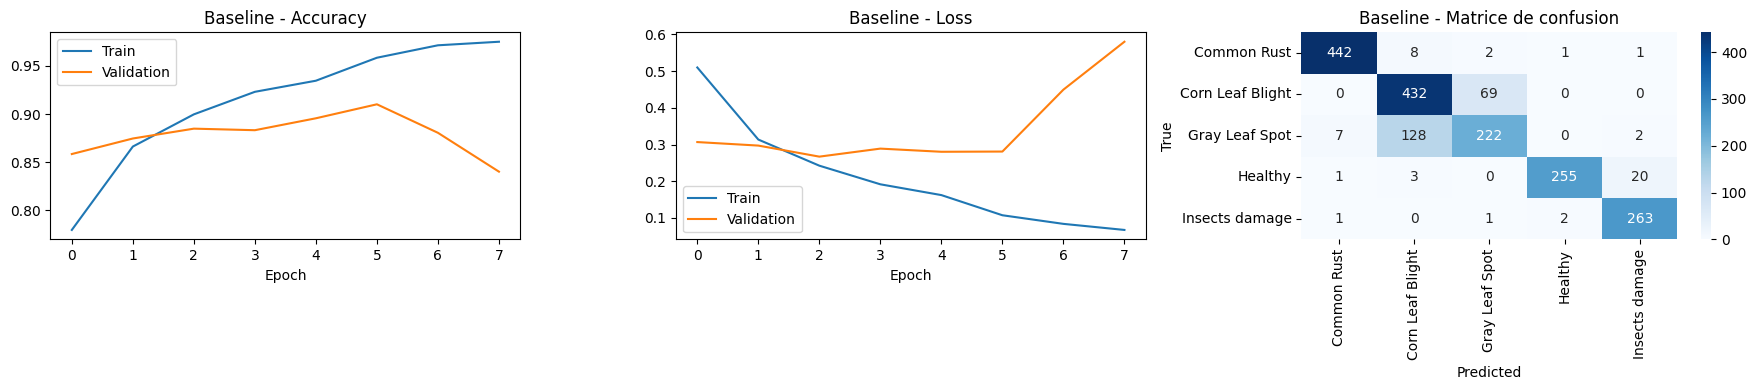


Class Weights | Test Acc=88.60% | Loss=0.2976 | Macro F1=0.894 | Val Acc=90.16%
                  precision    recall  f1-score   support

     Common Rust       0.98      0.97      0.98       454
Corn Leaf Blight       0.83      0.81      0.82       501
  Gray Leaf Spot       0.73      0.75      0.74       359
         Healthy       0.97      0.97      0.97       279
  Insects damage       0.94      0.97      0.96       267

        accuracy                           0.89      1860
       macro avg       0.89      0.90      0.89      1860
    weighted avg       0.89      0.89      0.89      1860



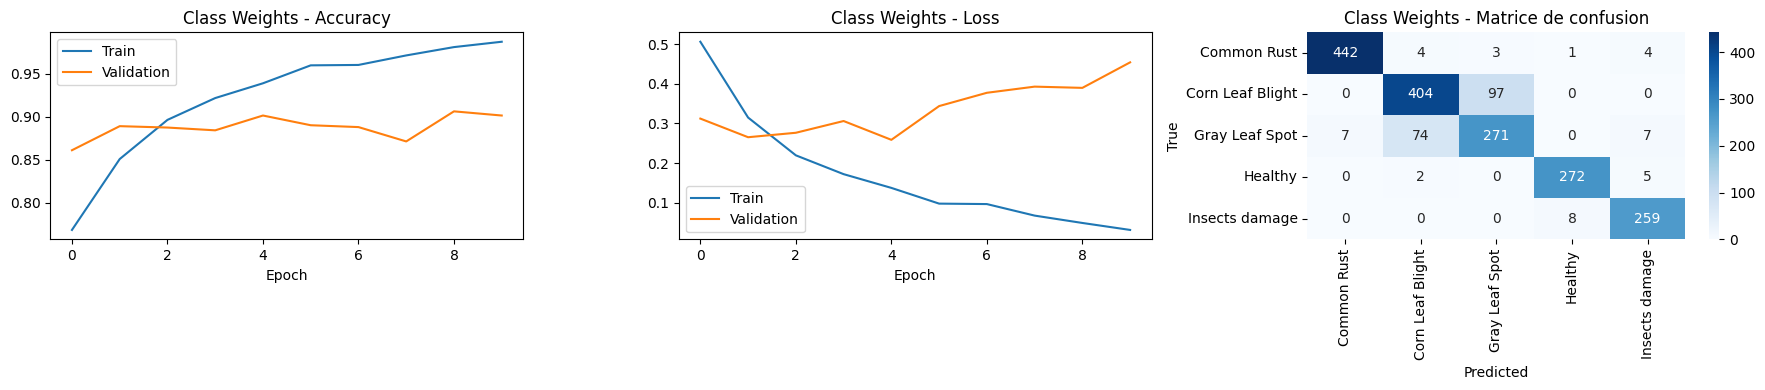


Augmentation | Test Acc=94.78% | Loss=0.1351 | Macro F1=0.950 | Val Acc=95.86%
                  precision    recall  f1-score   support

     Common Rust       0.98      0.99      0.99       454
Corn Leaf Blight       0.92      0.93      0.92       501
  Gray Leaf Spot       0.90      0.87      0.88       359
         Healthy       0.98      0.99      0.98       279
  Insects damage       0.99      0.97      0.98       267

        accuracy                           0.95      1860
       macro avg       0.95      0.95      0.95      1860
    weighted avg       0.95      0.95      0.95      1860



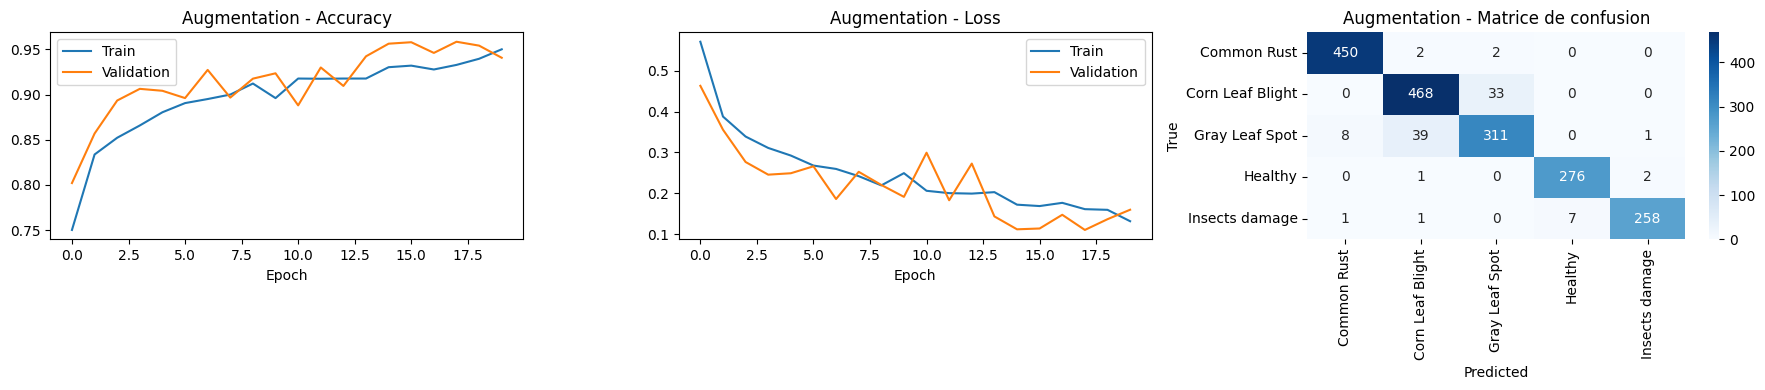


CW + Augmentation | Test Acc=93.71% | Loss=0.1622 | Macro F1=0.943 | Val Acc=95.16%
                  precision    recall  f1-score   support

     Common Rust       0.98      0.99      0.99       454
Corn Leaf Blight       0.96      0.83      0.89       501
  Gray Leaf Spot       0.80      0.94      0.86       359
         Healthy       0.99      0.99      0.99       279
  Insects damage       0.99      0.99      0.99       267

        accuracy                           0.94      1860
       macro avg       0.94      0.95      0.94      1860
    weighted avg       0.94      0.94      0.94      1860



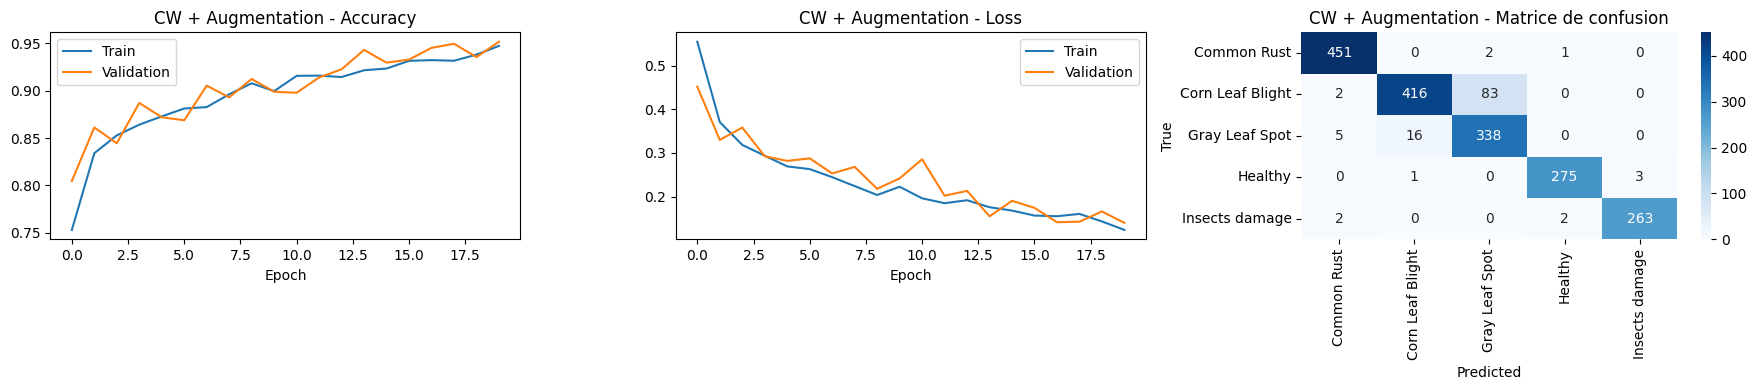


=== RÉCAPITULATIF LeNet (graine 42) ===
Expérience                        TestAcc  TestLoss  MacroF1   ValAcc
Baseline                           86.77%    0.2961    0.873   88.49%
Class Weights                      88.60%    0.2976    0.894   90.16%
Augmentation                       94.78%    0.1351    0.950   95.86%
CW + Augmentation                  93.71%    0.1622    0.943   95.16%

>>> Meilleure configuration (val acc) : Augmentation

Variante Max (Augmentation) | Test Acc=93.44% | Loss=0.1776 | Macro F1=0.940 | Val Acc=94.35%
                  precision    recall  f1-score   support

     Common Rust       0.98      1.00      0.99       454
Corn Leaf Blight       0.95      0.84      0.89       501
  Gray Leaf Spot       0.80      0.92      0.86       359
         Healthy       1.00      0.97      0.98       279
  Insects damage       0.98      0.97      0.97       267

        accuracy                           0.93      1860
       macro avg       0.94      0.94      0.94     

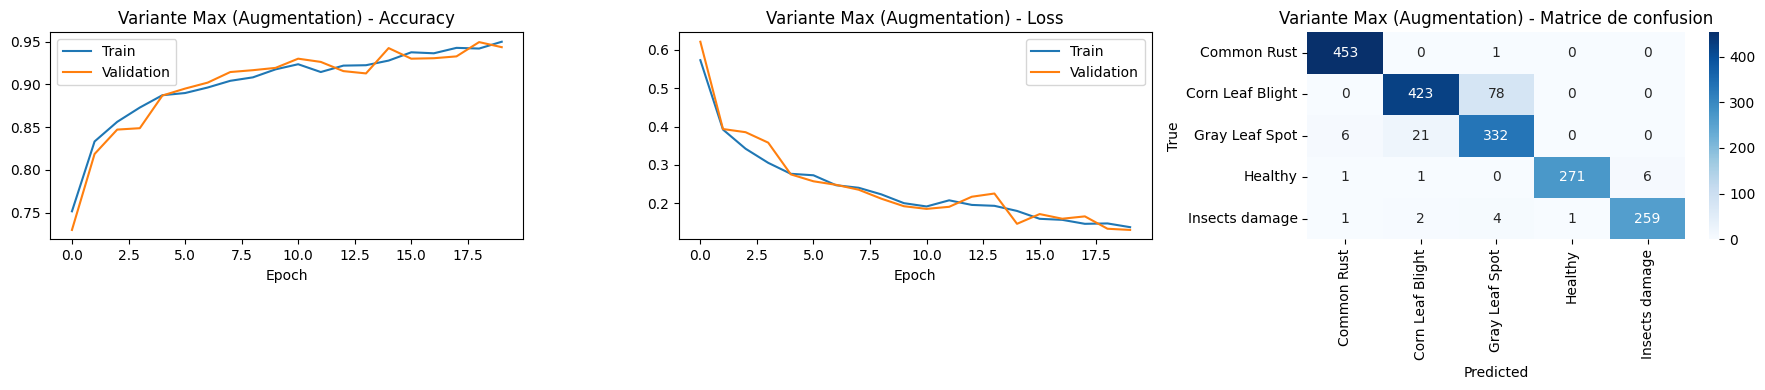


=== COMPARAISON FINALE LeNet vs Variante (graine 42) ===
Expérience                        TestAcc  TestLoss  MacroF1   ValAcc
Baseline                           86.77%    0.2961    0.873   88.49%
Class Weights                      88.60%    0.2976    0.894   90.16%
Augmentation                       94.78%    0.1351    0.950   95.86%
CW + Augmentation                  93.71%    0.1622    0.943   95.16%
Variante Max (Augmentation)        93.44%    0.1776    0.940   94.35%


In [6]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, AveragePooling2D, MaxPooling2D, Flatten,
                                     Dense, RandomFlip, RandomRotation, RandomZoom)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42  #la graine du hasard, identique pour tous les modèles
results, models, histories = {}, {}, {}   ## 3 dictionnaires vides : chiffres, modèles entraînés, historiques d'entraînement
#architecture
def build_lenet(pool, augment):
    layers = [tf.keras.Input(shape=(128, 128, 3))]
    if augment:
        layers += [RandomFlip("horizontal"), RandomRotation(0.1), RandomZoom(0.1)]
    layers += [
        Conv2D(6, (5, 5), activation='relu'), pool(pool_size=(2, 2)),
        Conv2D(16, (5, 5), activation='relu'), pool(pool_size=(2, 2)),
        Flatten(),
        Dense(120, activation='relu'),
        Dense(84, activation='relu'),
        Dense(5, activation='softmax')
    ]
    return Sequential(layers)

def run(name, pool, augment, use_cw):
    tf.keras.utils.set_random_seed(SEED)          # avant CHAQUE modèle
    m = build_lenet(pool, augment)
    m.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    h = m.fit(X_train_img, y_train, validation_data=(X_val_img, y_val),
              epochs=20, batch_size=32,
              class_weight=class_weights if use_cw else None,
              callbacks=[es], verbose=0)

    val_loss, val_acc = m.evaluate(X_val_img, y_val, verbose=0)
    test_loss, test_acc = m.evaluate(X_test_img, y_test, verbose=0)
    y_pred = np.argmax(m.predict(X_test_img, verbose=0), axis=1)
    f1 = f1_score(y_test, y_pred, average='macro')

    print(f"\n{'='*60}\n{name} | Test Acc={test_acc*100:.2f}% | "
          f"Loss={test_loss:.4f} | Macro F1={f1:.3f} | Val Acc={val_acc*100:.2f}%\n{'='*60}")
    print(classification_report(y_test, y_pred, target_names=classes))

    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    ax[0].plot(h.history['accuracy'], label='Train')
    ax[0].plot(h.history['val_accuracy'], label='Validation')
    ax[0].set_title(f'{name} - Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(h.history['loss'], label='Train')
    ax[1].plot(h.history['val_loss'], label='Validation')
    ax[1].set_title(f'{name} - Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes, ax=ax[2])
    ax[2].set_title(f'{name} - Matrice de confusion')
    ax[2].set_xlabel('Predicted'); ax[2].set_ylabel('True')
    plt.tight_layout(); plt.show()

    results[name] = dict(test_acc=test_acc, test_loss=test_loss, f1=f1, val_acc=val_acc)
    models[name], histories[name] = m, h

# ---------- A. Les 4 expériences LeNet (AveragePooling) ----------
configs = {
    "Baseline":          (False, False),   # (augment, class_weight)
    "Class Weights":     (False, True),
    "Augmentation":      (True,  False),
    "CW + Augmentation": (True,  True),
}
for name, (aug, cw) in configs.items():
    run(name, AveragePooling2D, aug, cw)

def print_table(title):
    print(f"\n=== {title} (graine {SEED}) ===")
    print(f"{'Expérience':32s} {'TestAcc':>8s} {'TestLoss':>9s} {'MacroF1':>8s} {'ValAcc':>8s}")
    for n, r in results.items():
        print(f"{n:32s} {r['test_acc']*100:7.2f}% {r['test_loss']:9.4f} "
              f"{r['f1']:8.3f} {r['val_acc']*100:7.2f}%")

print_table("RÉCAPITULATIF LeNet")

# ---------- B. Choix de la meilleure configuration ----------
# Critère : accuracy sur la VALIDATION (le test reste réservé à l'évaluation finale)
best_name = max(configs, key=lambda n: results[n]['val_acc'])
best_aug, best_cw = configs[best_name]
print(f"\n>>> Meilleure configuration (val acc) : {best_name}")

# ---------- C. Variante : seul changement AveragePooling -> MaxPooling ----------
variant_name = f"Variante Max ({best_name})"
run(variant_name, MaxPooling2D, best_aug, best_cw)

print_table("COMPARAISON FINALE LeNet vs Variante")

MobileNetV2 avec Variante :'ajouter une Dense(128, relu)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 61s 144ms/step - accuracy: 0.8839 - loss: 0.3139 - val_accuracy: 0.9381 - val_loss: 0.1710
Epoch 2/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9417 - loss: 0.1624 - val_accuracy: 0.9457 - val_loss: 0.1422
Epoch 3/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9542 - loss: 0.1304 - val_accuracy: 0.9478 - val_loss: 0.1305
Epoch 4/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9598 - loss: 0.1129 - val_accuracy: 0.9505 - val_loss: 0.1225
Epoch 5/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9637 - loss: 0.1010 - val_accuracy: 0.9505 - val_loss: 0.1171
Epoch 6/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9677 - loss: 0.0921 - val_accuracy: 0.9521 - val_loss: 0.1134
Epoch 7/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9704 - loss: 0.0852 - val_accuracy: 0.9521 - val_loss: 0.1110
Epoch 8/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 19m

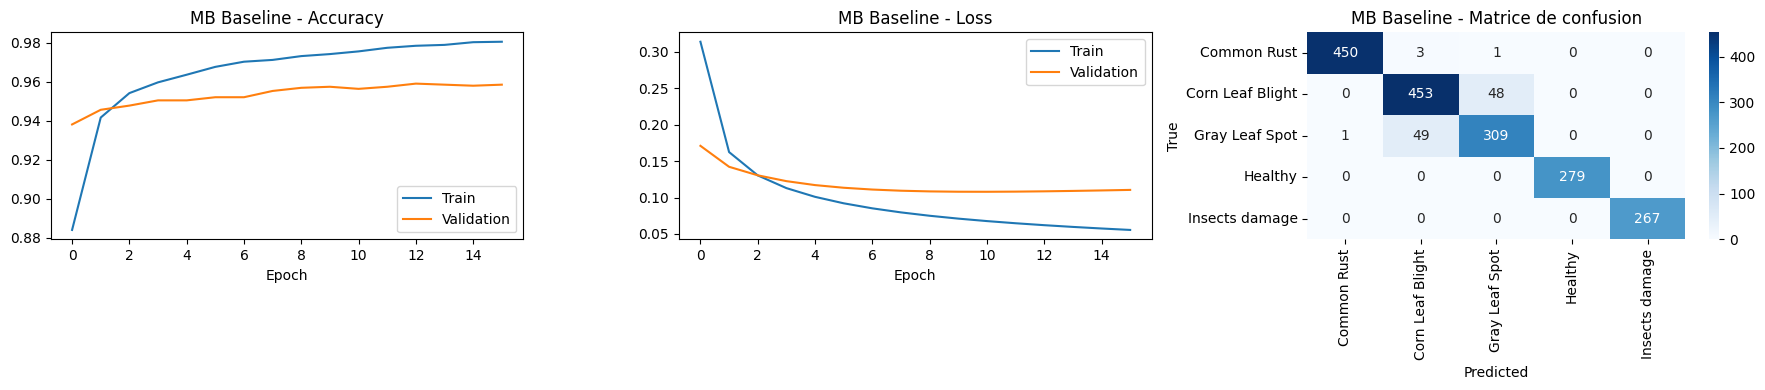

Epoch 1/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - accuracy: 0.8764 - loss: 0.2884 - val_accuracy: 0.9441 - val_loss: 0.1633
Epoch 2/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9389 - loss: 0.1444 - val_accuracy: 0.9478 - val_loss: 0.1367
Epoch 3/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9517 - loss: 0.1156 - val_accuracy: 0.9494 - val_loss: 0.1257
Epoch 4/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9587 - loss: 0.0998 - val_accuracy: 0.9521 - val_loss: 0.1188
Epoch 5/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9643 - loss: 0.0890 - val_accuracy: 0.9537 - val_loss: 0.1143
Epoch 6/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9676 - loss: 0.0811 - val_accuracy: 0.9537 - val_loss: 0.1113
Epoch 7/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9700 - loss: 0.0749 - val_accuracy: 0.9554 - val_loss: 0.1093
Epoch 8/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9721 - loss: 0.0699 - val_acc

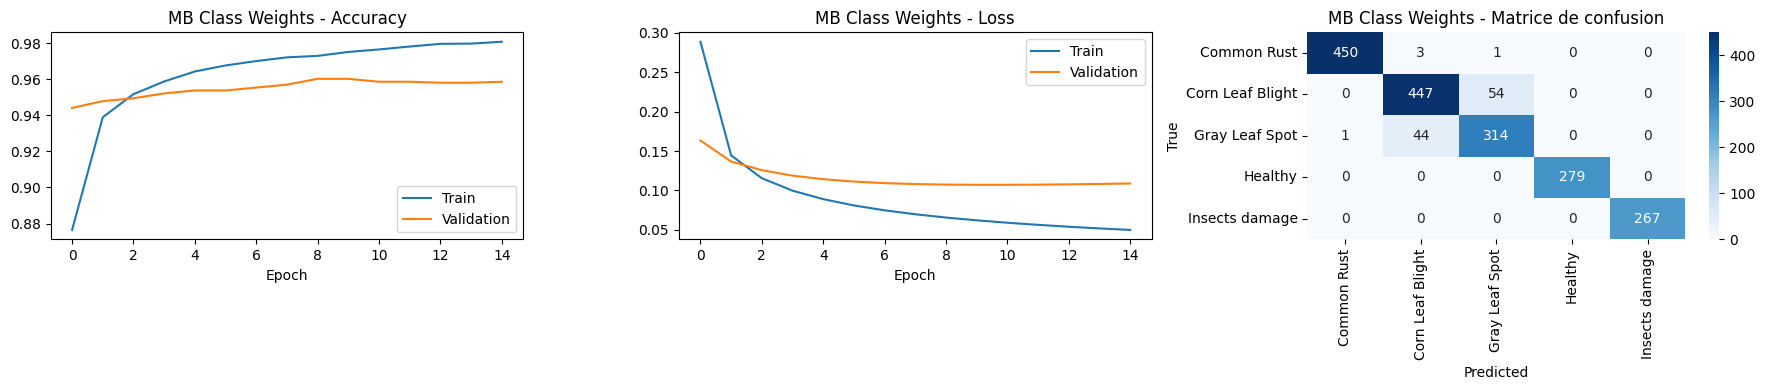

Epoch 1/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - accuracy: 0.8590 - loss: 0.3662 - val_accuracy: 0.9069 - val_loss: 0.2244
Epoch 2/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.9190 - loss: 0.2119 - val_accuracy: 0.9263 - val_loss: 0.1923
Epoch 3/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9261 - loss: 0.1895 - val_accuracy: 0.9328 - val_loss: 0.1732
Epoch 4/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.9280 - loss: 0.1773 - val_accuracy: 0.9295 - val_loss: 0.1740
Epoch 5/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.9327 - loss: 0.1695 - val_accuracy: 0.9274 - val_loss: 0.1643
Epoch 6/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.9351 - loss: 0.1579 - val_accuracy: 0.9338 - val_loss: 0.1617
Epoch 7/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9355 - loss: 0.1567 - val_accuracy: 0.9317 - val_loss: 0.1621
Epoch 8/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.9387 - loss: 0.1496 - val_ac

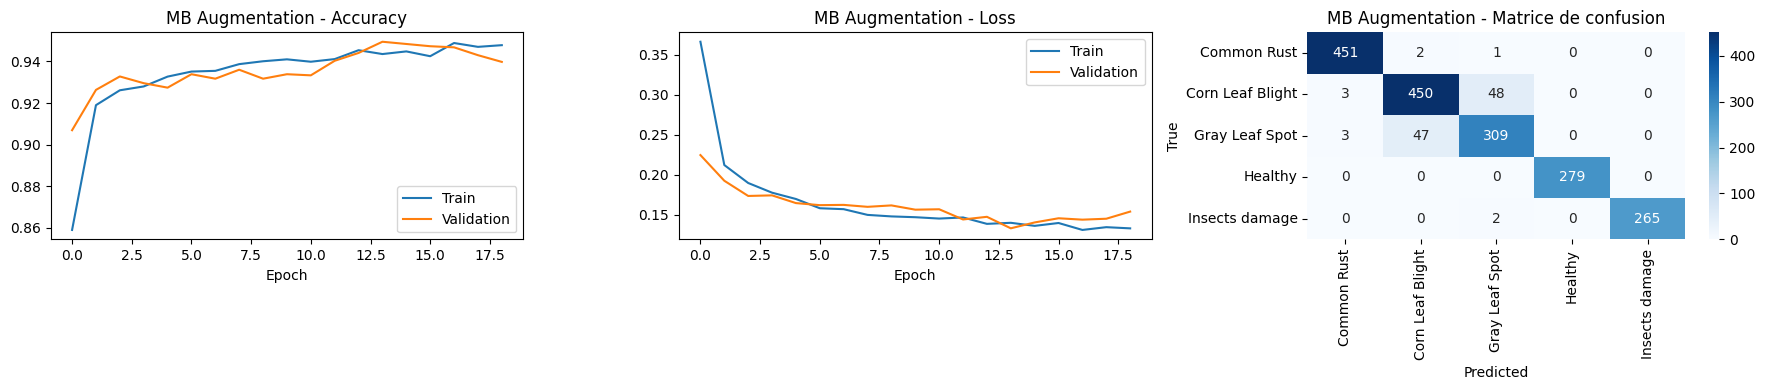

Epoch 1/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 16s 37ms/step - accuracy: 0.8555 - loss: 0.3358 - val_accuracy: 0.9155 - val_loss: 0.2150
Epoch 2/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9171 - loss: 0.1871 - val_accuracy: 0.9252 - val_loss: 0.1834
Epoch 3/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.9228 - loss: 0.1676 - val_accuracy: 0.9317 - val_loss: 0.1672
Epoch 4/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.9283 - loss: 0.1565 - val_accuracy: 0.9317 - val_loss: 0.1698
Epoch 5/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.9314 - loss: 0.1489 - val_accuracy: 0.9349 - val_loss: 0.1567
Epoch 6/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9336 - loss: 0.1384 - val_accuracy: 0.9354 - val_loss: 0.1546
Epoch 7/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.9335 - loss: 0.1371 - val_accuracy: 0.9344 - val_loss: 0.1572
Epoch 8/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9390 - loss: 0.1308 - val_ac

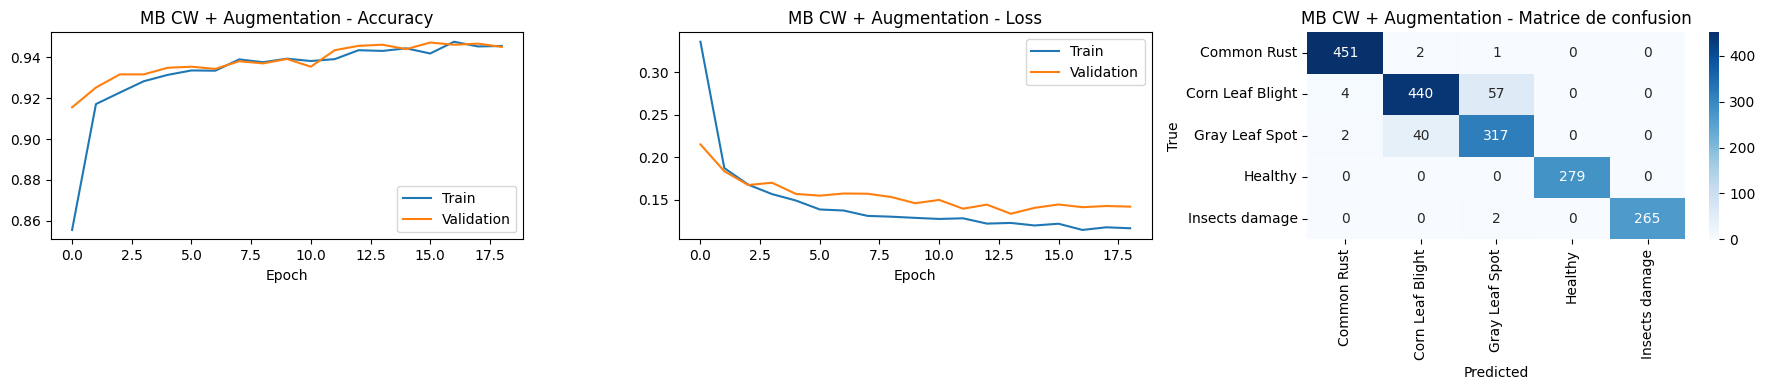


=== RÉCAPITULATIF MobileNetV2 (graine 42) ===
Expérience                                TestAcc  TestLoss  MacroF1   ValAcc
MB Baseline                                94.52%    0.1345    0.951   95.64%
MB Class Weights                           94.46%    0.1354    0.951   96.02%
MB Augmentation                            94.30%    0.1464    0.949   94.94%
MB CW + Augmentation                       94.19%    0.1495    0.949   94.62%

>>> Meilleure configuration MobileNetV2 (val acc) : MB Class Weights


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,201 (8.69 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 12,812 (50.05 KB)

Epoch 1/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 24s 56ms/step - accuracy: 0.9057 - loss: 0.2085 - val_accuracy: 0.9532 - val_loss: 0.1255
Epoch 2/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9511 - loss: 0.1063 - val_accuracy: 0.9570 - val_loss: 0.1152
Epoch 3/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9714 - loss: 0.0681 - val_accuracy: 0.9591 - val_loss: 0.1081
Epoch 4/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9822 - loss: 0.0463 - val_accuracy: 0.9607 - val_loss: 0.1097
Epoch 5/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.9887 - loss: 0.0303 - val_accuracy: 0.9666 - val_loss: 0.0892
Epoch 6/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9894 - loss: 0.0253 - val_accuracy: 0.9672 - val_loss: 0.0894
Epoch 7/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9892 - loss: 0.0258 - val_accuracy: 0.9726 - val_loss: 0.0840
Epoch 8/20
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9947 - loss: 0.0161 - val_acc

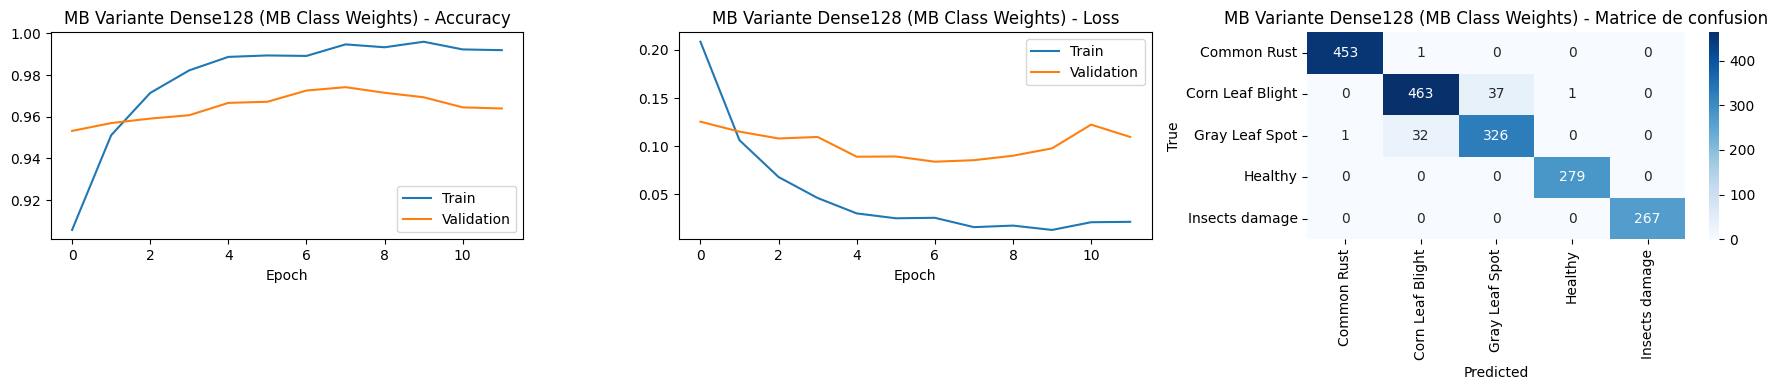

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,751,825 (10.50 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 329,228 (1.26 MB)


=== COMPARAISON FINALE MobileNetV2 vs Variante (graine 42) ===
Expérience                                TestAcc  TestLoss  MacroF1   ValAcc
MB Baseline                                94.52%    0.1345    0.951   95.64%
MB Class Weights                           94.46%    0.1354    0.951   96.02%
MB Augmentation                            94.30%    0.1464    0.949   94.94%
MB CW + Augmentation                       94.19%    0.1495    0.949   94.62%
MB Variante Dense128 (MB Class Weights)    96.13%    0.1154    0.966   97.26%


In [7]:
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Dense, GlobalAveragePooling2D, Rescaling,
                                     RandomFlip, RandomRotation, RandomZoom)
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
results_mb, models_mb, histories_mb = {}, {}, {}

def build_mobilenet(augment, extra_dense=False):
    base = MobileNetV2(input_shape=(128, 128, 3), include_top=False, weights='imagenet') #on prend les poids de couches convoltifs gelés et pas la classification
    base.trainable = False                       # backbone gelé
    layers = [tf.keras.Input(shape=(128, 128, 3))]
    if augment:
        layers += [RandomFlip("horizontal"), RandomRotation(0.1), RandomZoom(0.1)]
    layers += [
        Rescaling(2.0, offset=-1.0),             # [0,1] -> [-1,1] attendu par MobileNetV2
        base,
        GlobalAveragePooling2D(),
    ]
    if extra_dense:
        layers += [Dense(128, activation='relu')]    # seul élément ajouté dans la variante
    layers += [Dense(5, activation='softmax')]
    return Sequential(layers)

def run_mb(name, augment, use_cw, extra_dense=False):
    tf.keras.utils.set_random_seed(SEED)         # avant CHAQUE modèle
    m = build_mobilenet(augment, extra_dense)
    m.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    h = m.fit(X_train_img, y_train, validation_data=(X_val_img, y_val),
              epochs=20, batch_size=32,
              class_weight=class_weights if use_cw else None,
              callbacks=[es], verbose=1)

    val_loss, val_acc = m.evaluate(X_val_img, y_val, verbose=0)
    test_loss, test_acc = m.evaluate(X_test_img, y_test, verbose=0)
    y_pred = np.argmax(m.predict(X_test_img, verbose=0), axis=1)
    f1 = f1_score(y_test, y_pred, average='macro')

    print(f"\n{'='*60}\n{name} | Test Acc={test_acc*100:.2f}% | "
          f"Loss={test_loss:.4f} | Macro F1={f1:.3f} | Val Acc={val_acc*100:.2f}%\n{'='*60}")
    print(classification_report(y_test, y_pred, target_names=classes))

    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    ax[0].plot(h.history['accuracy'], label='Train')
    ax[0].plot(h.history['val_accuracy'], label='Validation')
    ax[0].set_title(f'{name} - Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(h.history['loss'], label='Train')
    ax[1].plot(h.history['val_loss'], label='Validation')
    ax[1].set_title(f'{name} - Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes, ax=ax[2])
    ax[2].set_title(f'{name} - Matrice de confusion')
    ax[2].set_xlabel('Predicted'); ax[2].set_ylabel('True')
    plt.tight_layout(); plt.show()

    results_mb[name] = dict(test_acc=test_acc, test_loss=test_loss, f1=f1, val_acc=val_acc)
    models_mb[name], histories_mb[name] = m, h

# ---------- A. Les 4 expériences MobileNetV2 ----------
configs_mb = {
    "MB Baseline":          (False, False),   # (augment, class_weight)
    "MB Class Weights":     (False, True),
    "MB Augmentation":      (True,  False),
    "MB CW + Augmentation": (True,  True),
}
for name, (aug, cw) in configs_mb.items():
    run_mb(name, aug, cw)

def print_table_mb(title):
    print(f"\n=== {title} (graine {SEED}) ===")
    print(f"{'Expérience':40s} {'TestAcc':>8s} {'TestLoss':>9s} {'MacroF1':>8s} {'ValAcc':>8s}")
    for n, r in results_mb.items():
        print(f"{n:40s} {r['test_acc']*100:7.2f}% {r['test_loss']:9.4f} "
              f"{r['f1']:8.3f} {r['val_acc']*100:7.2f}%")

print_table_mb("RÉCAPITULATIF MobileNetV2")

# ---------- B. Meilleure configuration (sur la VALIDATION) ----------
best_mb = max(configs_mb, key=lambda n: results_mb[n]['val_acc'])
best_aug_mb, best_cw_mb = configs_mb[best_mb]
print(f"\n>>> Meilleure configuration MobileNetV2 (val acc) : {best_mb}")
models_mb[best_mb].summary()

# ---------- C. Variante : ajout de Dense(128, relu) ----------
variant_mb = f"MB Variante Dense128 ({best_mb})"
run_mb(variant_mb, best_aug_mb, best_cw_mb, extra_dense=True)
models_mb[variant_mb].summary()

print_table_mb("COMPARAISON FINALE MobileNetV2 vs Variante")